In [1]:
from google.colab import files

uploaded = files.upload()

Saving news.zip to news.zip


In [2]:
from pathlib import PurePosixPath
from zipfile import ZipFile
from collections import Counter

zip_name = next(
    (name for name in uploaded if name.lower().endswith(".zip")),
    None
)

if zip_name is None:
    raise ValueError("Please upload news.zip first.")

with ZipFile(zip_name) as archive:
    file_names = [
        item.filename
        for item in archive.infolist()
        if not item.is_dir()
        and "__MACOSX" not in PurePosixPath(item.filename).parts
        and not PurePosixPath(item.filename).name.startswith(".")
    ]

    print("Number of files:", len(file_names))

    extensions = Counter(
        PurePosixPath(name).suffix.lower() or "(no extension)"
        for name in file_names
    )
    print("File types:", dict(extensions))

    print("\nFirst 15 file names:")
    for name in file_names[:15]:
        print(name)

    text_files = [
        name for name in file_names
        if name.lower().endswith(".txt")
    ]

    if text_files:
        sample_name = text_files[0]
        sample = archive.read(sample_name)

        print("\nSample article:", sample_name)
        print(sample.decode("utf-8-sig", errors="replace")[:1500])

Number of files: 10
File types: {'.txt': 10}

First 15 file names:
sa_news/news_1.txt
sa_news/news_10.txt
sa_news/news_2.txt
sa_news/news_3.txt
sa_news/news_4.txt
sa_news/news_5.txt
sa_news/news_6.txt
sa_news/news_7.txt
sa_news/news_8.txt
sa_news/news_9.txt

Sample article: sa_news/news_1.txt
Eskom former official, service provider appear in court
Tuesday, July 9, 2024

An Eskom former employee and a service provider at the power utility have appeared in the Hendrina Magistrates’ Court to face charges of theft and fraud.

The two made separate appearances at the court and were released on bail of R30 000 each.

The power utility explained that an investigation had revealed that between January and April last year, the service provider had supplied five valve stems to the Hendrina Power Station.

According to Eskom the valves “were stolen from the same power station warehouse, as a result of working with the Eskom employee”.

“An internal investigation revealed that the Eskom employee h

In [3]:
import pandas as pd
from zipfile import ZipFile
from pathlib import PurePosixPath

records = []

with ZipFile(zip_name) as archive:
    for name in sorted(text_files):
        raw_bytes = archive.read(name)

        try:
            content = raw_bytes.decode("utf-8-sig")
        except UnicodeDecodeError:
            content = raw_bytes.decode("cp1252")

        records.append({
            "file_name": PurePosixPath(name).name,
            "content": content
        })

df = pd.DataFrame(records, columns=["file_name", "content"])

print("DataFrame shape:", df.shape)
display(df)

DataFrame shape: (10, 2)


,file_name,content
0,news_1.txt,"Eskom former official, service provider appear..."
1,news_10.txt,"Wet, cold weather expected to continue in West..."
2,news_2.txt,Gauteng Education commits to implementing Mayi...
3,news_3.txt,New Labour Minister charts the way forward \r\...
4,news_4.txt,Police recue two kidnapped victims in Benoni\r...
5,news_5.txt,President Ramaphosa sends condolences to decea...
6,news_6.txt,Accounting officers must be accountable for no...
7,news_7.txt,Democratic dispensation necessitated a complet...
8,news_8.txt,Trust and relationships key ingredients to coa...
9,news_9.txt,PSC applauds officials who refuse to accept a ...


In [4]:
empty_mask = df["content"].str.strip().eq("")
duplicate_mask = df["content"].str.strip().duplicated()

print("Empty articles:", empty_mask.sum())
print("Duplicate articles:", duplicate_mask.sum())

Empty articles: 0
Duplicate articles: 0


In [5]:
processed_df = df.loc[
    ~empty_mask & ~duplicate_mask
].copy().reset_index(drop=True)

print("Articles retained:", len(processed_df))

Articles retained: 10


In [6]:
import re
import html
import unicodedata
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

news_stopwords = {"said", "says", "according"}

stop_words = set(ENGLISH_STOP_WORDS) | news_stopwords

date_line_pattern = (
    r"(?im)^[ \t]*"
    r"(?:Monday|Tuesday|Wednesday|Thursday|Friday|Saturday|Sunday)"
    r",?\s+"
    r"(?:January|February|March|April|May|June|July|August|"
    r"September|October|November|December)"
    r"\s+\d{1,2},?\s+\d{4}[ \t]*$"
)

def clean_text(text):
    text = unicodedata.normalize("NFKC", html.unescape(text))

    text = re.sub(date_line_pattern, " ", text)

    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.\w+\b", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)

    text = text.lower()

    text = re.sub(r"['’]s\b", "", text)

    tokens = re.findall(r"[^\W\d_]+", text, flags=re.UNICODE)

    tokens = [
        word for word in tokens
        if len(word) >= 3 and word not in stop_words
    ]

    return " ".join(tokens)

In [7]:
processed_df["clean_content"] = (
    processed_df["content"].apply(clean_text)
)

processed_df["original_word_count"] = (
    processed_df["content"].str.split().str.len()
)

processed_df["clean_word_count"] = (
    processed_df["clean_content"].str.split().str.len()
)

display(
    processed_df[
        ["file_name", "original_word_count", "clean_word_count"]
    ]
)

if not processed_df.empty:
    print("ORIGINAL ARTICLE:\n")
    print(processed_df.loc[0, "content"][:1200])

    print("\nCLEANED ARTICLE:\n")
    print(processed_df.loc[0, "clean_content"][:1200])

print(
    "\nArticles empty after cleaning:",
    processed_df["clean_word_count"].eq(0).sum()
)

,file_name,original_word_count,clean_word_count
0,news_1.txt,237,126
1,news_10.txt,445,242
2,news_2.txt,285,155
3,news_3.txt,633,340
4,news_4.txt,215,118
5,news_5.txt,257,130
6,news_6.txt,450,229
7,news_7.txt,241,144
8,news_8.txt,720,393
9,news_9.txt,349,194


ORIGINAL ARTICLE:

Eskom former official, service provider appear in court
Tuesday, July 9, 2024

An Eskom former employee and a service provider at the power utility have appeared in the Hendrina Magistrates’ Court to face charges of theft and fraud.

The two made separate appearances at the court and were released on bail of R30 000 each.

The power utility explained that an investigation had revealed that between January and April last year, the service provider had supplied five valve stems to the Hendrina Power Station.

According to Eskom the valves “were stolen from the same power station warehouse, as a result of working with the Eskom employee”.

“An internal investigation revealed that the Eskom employee had misused company resources without authorisation for their own personal gain and also falsified documents as the end-user.”
The Eskom employee resigned while a disciplinary action was being instituted.

“Eskom suffered a financial loss of R667 500 because of this criminal 

In [8]:
processed_df = df.loc[
    ~empty_mask & ~duplicate_mask
].copy().reset_index(drop=True)

print("Articles retained:", len(processed_df))

Articles retained: 10


In [9]:
import re
import html
import unicodedata
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

news_stopwords = {"said", "says", "according"}

stop_words = set(ENGLISH_STOP_WORDS) | news_stopwords

date_line_pattern = (
    r"(?im)^[ \t]*"
    r"(?:Monday|Tuesday|Wednesday|Thursday|Friday|Saturday|Sunday)"
    r",?\s+"
    r"(?:January|February|March|April|May|June|July|August|"
    r"September|October|November|December)"
    r"\s+\d{1,2},?\s+\d{4}[ \t]*$"
)

def clean_text(text):
    text = unicodedata.normalize("NFKC", html.unescape(text))

    text = re.sub(date_line_pattern, " ", text)

    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.\w+\b", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)

    text = text.lower()

    text = re.sub(r"['’]s\b", "", text)

    tokens = re.findall(r"[^\W\d_]+", text, flags=re.UNICODE)

    tokens = [
        word for word in tokens
        if len(word) >= 3 and word not in stop_words
    ]

    return " ".join(tokens)

In [10]:
processed_df["clean_content"] = (
    processed_df["content"].apply(clean_text)
)

processed_df["original_word_count"] = (
    processed_df["content"].str.split().str.len()
)

processed_df["clean_word_count"] = (
    processed_df["clean_content"].str.split().str.len()
)

display(
    processed_df[
        ["file_name", "original_word_count", "clean_word_count"]
    ]
)

if not processed_df.empty:
    print("ORIGINAL ARTICLE:\n")
    print(processed_df.loc[0, "content"][:1200])

    print("\nCLEANED ARTICLE:\n")
    print(processed_df.loc[0, "clean_content"][:1200])

print(
    "\nArticles empty after cleaning:",
    processed_df["clean_word_count"].eq(0).sum()
)

,file_name,original_word_count,clean_word_count
0,news_1.txt,237,126
1,news_10.txt,445,242
2,news_2.txt,285,155
3,news_3.txt,633,340
4,news_4.txt,215,118
5,news_5.txt,257,130
6,news_6.txt,450,229
7,news_7.txt,241,144
8,news_8.txt,720,393
9,news_9.txt,349,194


ORIGINAL ARTICLE:

Eskom former official, service provider appear in court
Tuesday, July 9, 2024

An Eskom former employee and a service provider at the power utility have appeared in the Hendrina Magistrates’ Court to face charges of theft and fraud.

The two made separate appearances at the court and were released on bail of R30 000 each.

The power utility explained that an investigation had revealed that between January and April last year, the service provider had supplied five valve stems to the Hendrina Power Station.

According to Eskom the valves “were stolen from the same power station warehouse, as a result of working with the Eskom employee”.

“An internal investigation revealed that the Eskom employee had misused company resources without authorisation for their own personal gain and also falsified documents as the end-user.”
The Eskom employee resigned while a disciplinary action was being instituted.

“Eskom suffered a financial loss of R667 500 because of this criminal 

In [11]:
date_line_pattern = (
    r"(?i)\b"
    r"(?:Monday|Tuesday|Wednesday|Thursday|Friday|Saturday|Sunday)"
    r",?\s+"
    r"(?:January|February|March|April|May|June|July|August|"
    r"September|October|November|December)"
    r"\s+\d{1,2},?\s+\d{4}\b"
)

stop_words.update({"sanews", "gov"})

processed_df["clean_content"] = processed_df["content"].apply(clean_text)

processed_df["clean_word_count"] = (
    processed_df["clean_content"].str.split().str.len()
)

assert processed_df["clean_word_count"].gt(0).all(), (
    "At least one article became empty after cleaning."
)

display(
    processed_df[
        ["file_name", "original_word_count", "clean_word_count"]
    ]
)

print(processed_df.loc[0, "clean_content"])

,file_name,original_word_count,clean_word_count
0,news_1.txt,237,122
1,news_10.txt,445,238
2,news_2.txt,285,151
3,news_3.txt,633,336
4,news_4.txt,215,114
5,news_5.txt,257,126
6,news_6.txt,450,225
7,news_7.txt,241,140
8,news_8.txt,720,389
9,news_9.txt,349,190


eskom official service provider appear court eskom employee service provider power utility appeared hendrina magistrates court face charges theft fraud separate appearances court released bail power utility explained investigation revealed january april year service provider supplied valve stems hendrina power station eskom valves stolen power station warehouse result working eskom employee internal investigation revealed eskom employee misused company resources authorisation personal gain falsified documents end user eskom employee resigned disciplinary action instituted eskom suffered financial loss criminal activity eskom eskom acting general manager security botse sikhwitshi vowed power utility continue root criminality ranks eskom strongly condemns fraudulent activity business operations tolerate behaviour internal security investigations team continue collaborating south african police service ensuring enrich eskom expense held accountable sikhwitshi expected court july


In [12]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(
    min_df=1,
    max_df=0.95
)

X = vectorizer.fit_transform(processed_df["clean_content"])
feature_names = vectorizer.get_feature_names_out()

print("Number of articles:", X.shape[0])
print("Number of words in vocabulary:", X.shape[1])

assert np.all(np.asarray(X.sum(axis=1)).ravel() > 0), (
    "At least one article has no words after vectorization."
)

# Show a small part of the count matrix.
preview = pd.DataFrame(
    X[:5, :10].toarray(),
    index=processed_df["file_name"].iloc[:5],
    columns=feature_names[:10]
)

display(preview)

Number of articles: 10
Number of words in vocabulary: 1045


,abandoned,abroad,accept,acceptance,access,accountability,accountable,accounting,achieved,acknowledged
file_name,,,,,,,,,,
news_1.txt,0,0,0,0,0,0,1,0,0,0
news_10.txt,0,0,0,0,0,0,0,0,0,0
news_2.txt,0,0,0,0,0,0,0,0,0,1
news_3.txt,0,0,0,0,0,0,0,0,1,0
news_4.txt,0,0,0,0,0,0,0,0,0,0


In [13]:
from sklearn.decomposition import LatentDirichletAllocation

n_topics = 3
k_words = 10

lda = LatentDirichletAllocation(
    n_components=n_topics,
    learning_method="batch",
    max_iter=50,
    random_state=42
)

document_topic_distribution = lda.fit_transform(X)

print("LDA training completed.")
print("Topics:", n_topics)
print("Top words to display per topic:", k_words)

LDA training completed.
Topics: 3
Top words to display per topic: 10


In [14]:
topic_word_distribution = (
    lda.components_
    / lda.components_.sum(axis=1, keepdims=True)
)

topic_rows = []

for topic_index, probabilities in enumerate(topic_word_distribution):
    top_indices = probabilities.argsort()[::-1][:k_words]

    for rank, word_index in enumerate(top_indices, start=1):
        topic_rows.append({
            "topic": f"Topic {topic_index + 1}",
            "rank": rank,
            "word": feature_names[word_index],
            "probability": probabilities[word_index],
            "percentage": probabilities[word_index] * 100
        })

topics_df = pd.DataFrame(topic_rows)

for topic_name, table in topics_df.groupby("topic", sort=False):
    print(f"\n{topic_name}")
    display(
        table[["rank", "word", "probability", "percentage"]]
        .reset_index(drop=True)
        .round(4)
    )


Topic 1


,rank,word,probability,percentage
0,1,public,0.0148,1.4800
1,2,government,0.0103,1.0305
2,3,department,0.0103,1.0303
3,4,invoices,0.0097,0.9742
4,5,national,0.0086,0.8619
5,6,service,0.0081,0.8056
6,7,coalition,0.0075,0.7494
7,8,days,0.0069,0.6932
8,9,administration,0.0069,0.6932
9,10,africa,0.0069,0.6932



Topic 2


,rank,word,probability,percentage
0,1,police,0.0159,1.5869
1,2,kidnappers,0.0094,0.9372
2,3,victims,0.0072,0.7214
3,4,old,0.0051,0.5052
4,5,year,0.0051,0.5051
5,6,force,0.0050,0.5050
6,7,communities,0.0050,0.5049
7,8,monday,0.0050,0.5049
8,9,task,0.0050,0.5049
9,10,team,0.0050,0.5048



Topic 3


,rank,word,probability,percentage
0,1,eskom,0.0148,1.4782
1,2,cape,0.0100,0.9988
2,3,expected,0.0088,0.8792
3,4,western,0.0088,0.8789
4,5,weather,0.0088,0.8789
5,6,cold,0.0088,0.8789
6,7,west,0.0088,0.8789
7,8,service,0.0076,0.7592
8,9,department,0.0076,0.7592
9,10,sandf,0.0076,0.7591


In [15]:
topic_columns = [
    f"Topic {i + 1}" for i in range(n_topics)
]

document_topics_df = pd.DataFrame(
    document_topic_distribution,
    columns=topic_columns
)

document_topics_df.insert(
    0,
    "file_name",
    processed_df["file_name"].to_numpy()
)

document_topics_df["dominant_topic"] = (
    document_topics_df[topic_columns].idxmax(axis=1)
)

display(document_topics_df.round(4))

topic_prevalence = pd.DataFrame({
    "topic": topic_columns,
    "mean_document_share_percent": (
        document_topic_distribution.mean(axis=0) * 100
    )
}).sort_values(
    "mean_document_share_percent",
    ascending=False
)

display(topic_prevalence.round(2))

,file_name,Topic 1,Topic 2,Topic 3,dominant_topic
0,news_1.txt,0.0028,0.0028,0.9944,Topic 3
1,news_10.txt,0.0015,0.0014,0.9971,Topic 3
2,news_2.txt,0.9955,0.0023,0.0023,Topic 1
3,news_3.txt,0.9980,0.0010,0.0010,Topic 1
4,news_4.txt,0.0030,0.9940,0.0030,Topic 2
5,news_5.txt,0.0027,0.0027,0.9946,Topic 3
6,news_6.txt,0.9970,0.0015,0.0015,Topic 1
7,news_7.txt,0.9952,0.0024,0.0024,Topic 1
8,news_8.txt,0.9982,0.0009,0.0009,Topic 1
9,news_9.txt,0.9964,0.0018,0.0018,Topic 1


,topic,mean_document_share_percent
0,Topic 1,59.90
2,Topic 3,29.99
1,Topic 2,10.11


In [16]:
%pip -q install wordcloud

In [17]:
import matplotlib.pyplot as plt
import numpy as np
from wordcloud import WordCloud
from pathlib import Path

output_folder = Path("question2_outputs")
output_folder.mkdir(exist_ok=True)

topic_labels = {
    "Topic 1": "Government and public administration",
    "Topic 2": "Policing and kidnapping",
    "Topic 3": "Mixed: Eskom, weather and military news"
}

topic_colors = {
    "Topic 1": "#2563EB",
    "Topic 2": "#059669",
    "Topic 3": "#D97706"
}

topic_names = topics_df["topic"].drop_duplicates().tolist()

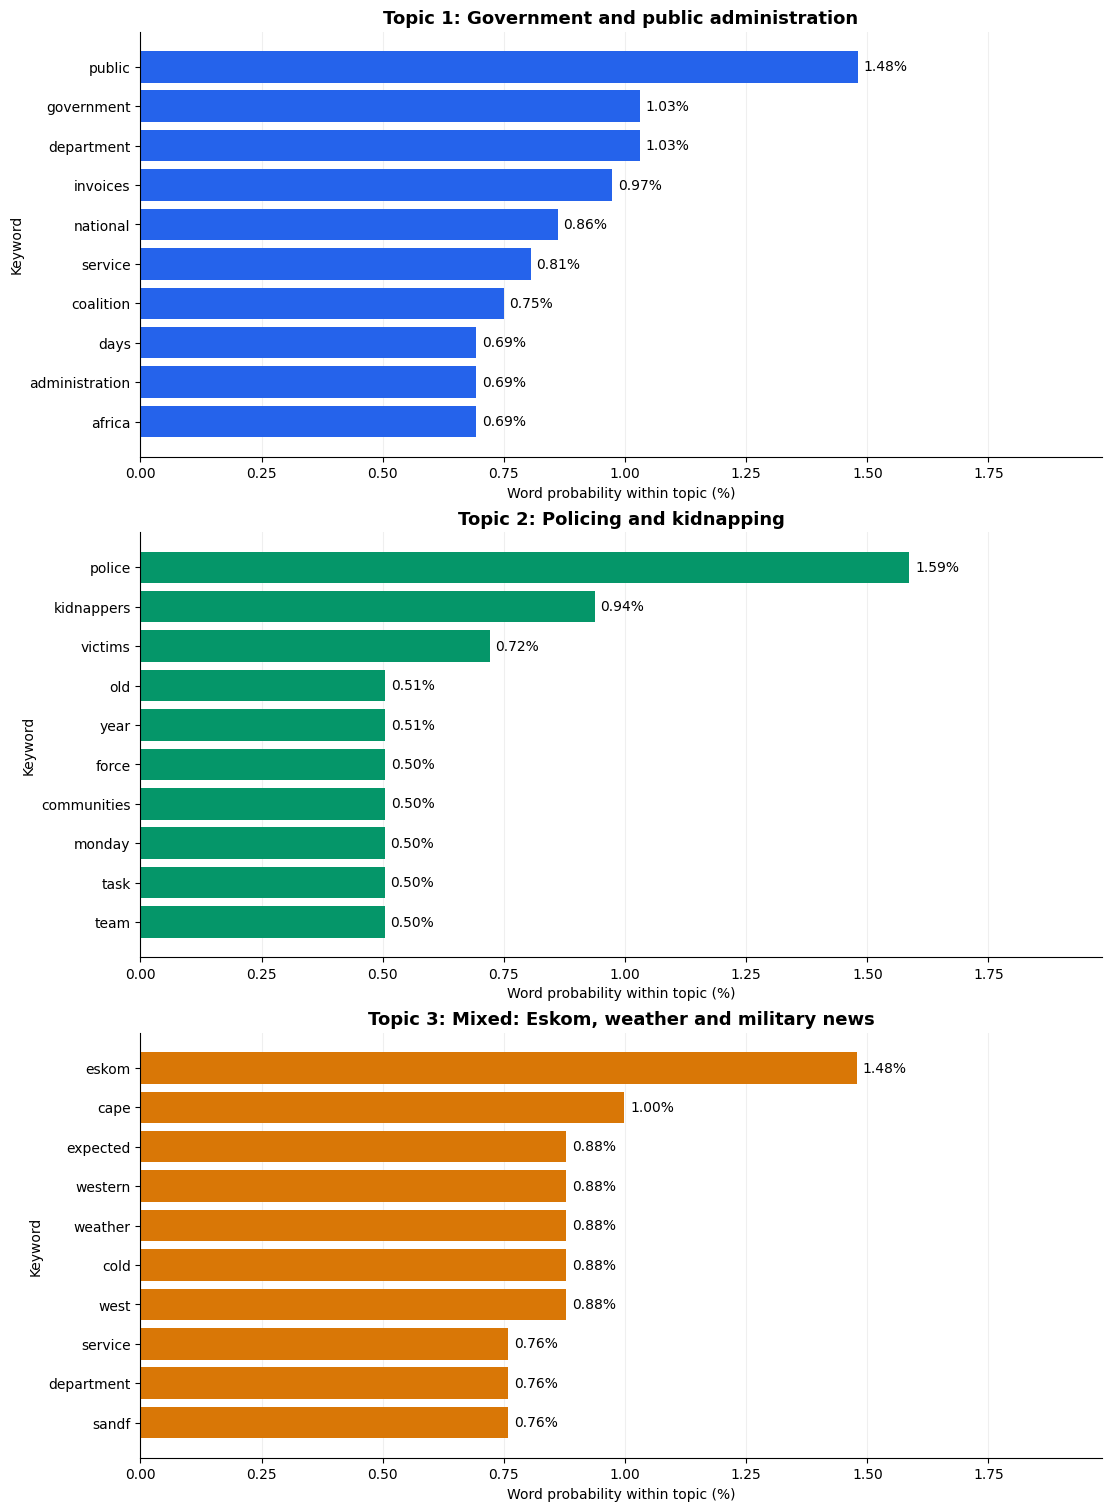

In [18]:
fig, axes = plt.subplots(
    nrows=len(topic_names),
    ncols=1,
    figsize=(11, 5 * len(topic_names)),
    constrained_layout=True
)

axes = np.atleast_1d(axes)

max_percentage = topics_df["percentage"].max()

for ax, topic_name in zip(axes, topic_names):
    topic_data = (
        topics_df[topics_df["topic"] == topic_name]
        .sort_values("probability", ascending=False)
    )

    bars = ax.barh(
        topic_data["word"],
        topic_data["percentage"],
        color=topic_colors[topic_name]
    )

    ax.invert_yaxis()

    ax.set_title(
        f"{topic_name}: {topic_labels[topic_name]}",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Word probability within topic (%)")
    ax.set_ylabel("Keyword")
    ax.set_xlim(0, max_percentage * 1.25)

    ax.bar_label(
        bars,
        labels=[
            f"{value:.2f}%"
            for value in topic_data["percentage"]
        ],
        padding=4
    )

    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.savefig(
    output_folder / "topic_keyword_bar_charts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

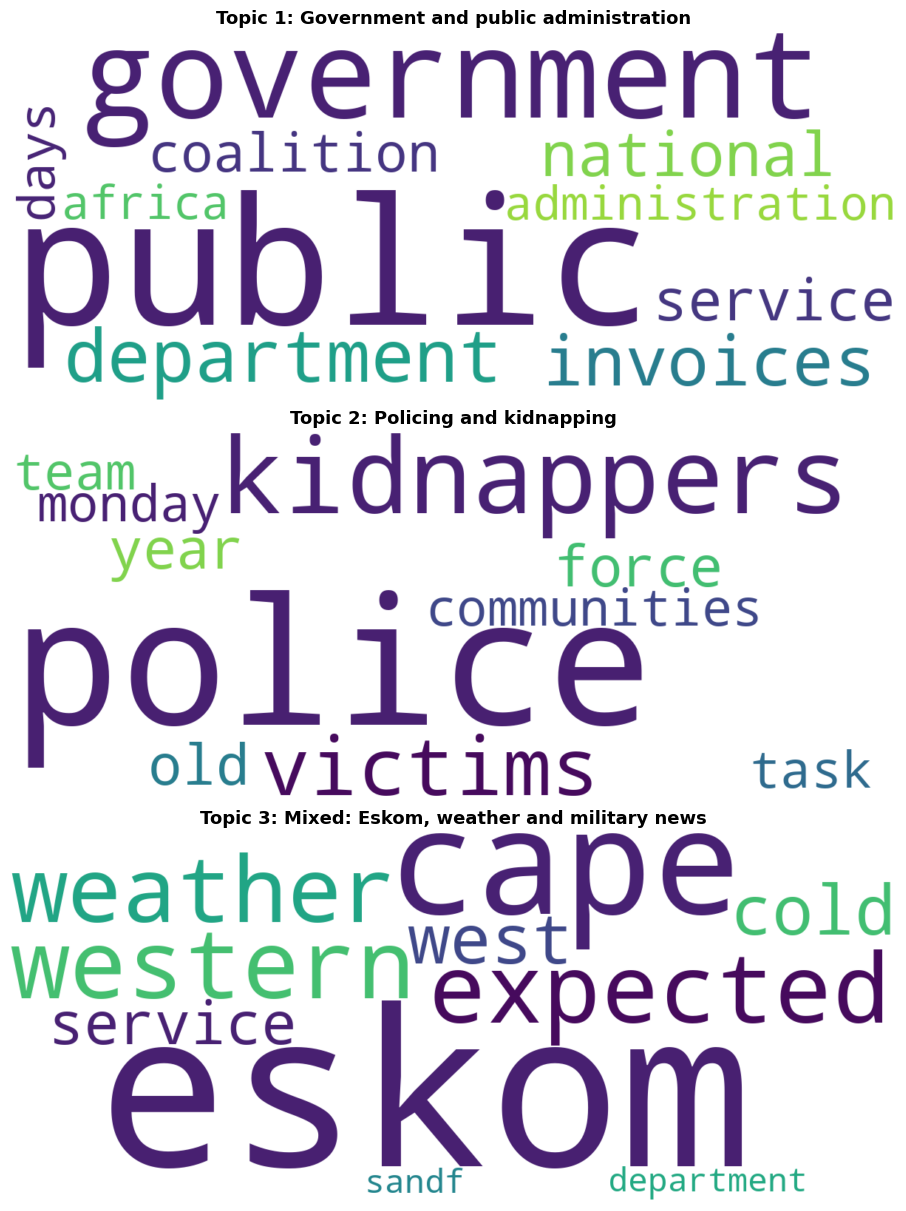

In [19]:
fig, axes = plt.subplots(
    nrows=len(topic_names),
    ncols=1,
    figsize=(12, 4 * len(topic_names)),
    constrained_layout=True
)

axes = np.atleast_1d(axes)

for ax, topic_name in zip(axes, topic_names):
    topic_data = topics_df[
        topics_df["topic"] == topic_name
    ]

    word_weights = dict(
        zip(
            topic_data["word"],
            topic_data["probability"]
        )
    )

    cloud = WordCloud(
        width=1200,
        height=500,
        background_color="white",
        colormap="viridis",
        max_words=k_words,
        relative_scaling=1.0,
        random_state=42
    ).generate_from_frequencies(word_weights)

    ax.imshow(cloud, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(
        f"{topic_name}: {topic_labels[topic_name]}",
        fontsize=13,
        fontweight="bold"
    )

fig.savefig(
    output_folder / "topic_word_clouds.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
df.to_csv(
    output_folder / "news_dataframe.csv",
    index=False
)

processed_df.to_csv(
    output_folder / "preprocessed_news.csv",
    index=False
)

topics_df.to_csv(
    output_folder / "top_words_per_topic.csv",
    index=False
)

document_topics_df.to_csv(
    output_folder / "document_topic_distribution.csv",
    index=False
)

topic_prevalence.to_csv(
    output_folder / "topic_prevalence.csv",
    index=False
)

pd.DataFrame(
    topic_word_distribution,
    index=topic_names,
    columns=feature_names
).to_csv(
    output_folder / "full_topic_word_distribution.csv",
    index_label="topic"
)

import shutil
from google.colab import files

shutil.make_archive(
    "Question_2_Results",
    "zip",
    root_dir=output_folder
)

files.download("Question_2_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>